# Task-3 Week-4.

**Dataset :-** 'Admission_Prediction.csv'

**Objective :- To visualize hierarchical relationships among university applicants using dendrograms generated through hierarchical clustering, identify groups of applicants with similar academic profiles, and discover hidden patterns and segmentation opportunities.

In [ ]:
# Import Library.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering


In [4]:
# Load the dataset

df = pd.read_csv("Admission_Prediction.csv")

print("Dataset loaded successfully.")

print("Dataset shape:", df.shape)

print("\nFirst five rows:")
print(df.head())

Dataset loaded successfully.
Dataset shape: (1000, 17)

First five rows:
   Serial No.  GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  \
0         104        317          104                  2  4.5  4.0  8.47   
1         170        311           99                  2  2.5  3.0  7.98   
2         138        316          100                  2  1.5  3.0  8.16   
3         147        315          105                  3  2.0  2.5  8.48   
4         117        299          102                  3  4.0  3.5  8.62   

   Research  Chance of Admit  Year Application_Date  \
0         0             0.57  2022       03-01-2022   
1         0             0.65  2022       09-01-2022   
2         1             0.71  2022       12-01-2022   
3         0             0.75  2022       13-01-2022   
4         0             0.56  2022       14-01-2022   

                         University_Name region Admission Status  \
0  Indian Institute of Technology Bombay   West         Rejected   
1  

In [5]:
# Examine the dataset columns

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

Column names:
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Year', 'Application_Date', 'University_Name', 'region', 'Admission Status', 'Duration_Months', 'Dropout_Event', 'Dropout-free survival']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Serial No.             1000 non-null   int64  
 1   GRE Score              1000 non-null   int64  
 2   TOEFL Score            1000 non-null   int64  
 3   University Rating      1000 non-null   int64  
 4   SOP                    1000 non-null   float64
 5   LOR                    1000 non-null   float64
 6   CGPA                   1000 non-null   float64
 7   Research               1000 non-null   int64  
 8   Chance of Admit        1000 non-null   float64
 9   Year                   100

In [6]:
# Select the applicant features

features = [
    "GRE Score",
    "TOEFL Score",
    "University Rating",
    "SOP",
    "LOR",
    "CGPA",
    "Research"
]

# Check whether all required features exist
missing_columns = [
    col for col in features
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"These columns were not found: {missing_columns}. "
        "Check the actual column names printed in Step 5."
    )

# Create a separate dataset for clustering
X = df[features].copy()

# Convert features to numeric values
for col in features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Replace infinite values and remove incomplete rows
X = X.replace([np.inf, -np.inf], np.nan)
valid_rows = X.notna().all(axis=1)

X = X.loc[valid_rows].copy()

# Keep the original applicant rows aligned with X
df_clean = df.loc[valid_rows].copy()

print("Selected features:")
print(X.head())

print("\nRows available for clustering:", len(X))

Selected features:
   GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  Research
0        317          104                  2  4.5  4.0  8.47         0
1        311           99                  2  2.5  3.0  7.98         0
2        316          100                  2  1.5  3.0  8.16         1
3        315          105                  3  2.0  2.5  8.48         0
4        299          102                  3  4.0  3.5  8.62         0

Rows available for clustering: 1000


In [8]:
# Standardize the features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features,
    index=X.index
)

print("Standardized features:")
print(X_scaled.head())

print("\nMean of standardized features:")
print(X_scaled.mean().round(2))

print("\nStandard deviation:")
print(X_scaled.std().round(2))

Standardized features:
   GRE Score  TOEFL Score  University Rating       SOP       LOR      CGPA  \
0   0.077187    -0.336022          -0.770627  1.077656  0.665569 -0.195779   
1  -0.370275    -0.991290          -0.770627 -0.870208 -0.456240 -0.996611   
2   0.002610    -0.860237          -0.770627 -1.844140 -0.456240 -0.702428   
3  -0.071967    -0.204968          -0.011389 -1.357174 -1.017144 -0.179435   
4  -1.265200    -0.598129          -0.011389  0.590690  0.104665  0.049374   

   Research  
0 -1.006018  
1 -1.006018  
2  0.994018  
3 -1.006018  
4 -1.006018  

Mean of standardized features:
GRE Score            0.0
TOEFL Score          0.0
University Rating   -0.0
SOP                  0.0
LOR                  0.0
CGPA                 0.0
Research            -0.0
dtype: float64

Standard deviation:
GRE Score            1.0
TOEFL Score          1.0
University Rating    1.0
SOP                  1.0
LOR                  1.0
CGPA                 1.0
Research             1.0
dtype:

In [21]:
# Generate the hierarchical clustering linkage

from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage

Z = linkage(
    X_scaled,
    method="ward",
    metric="euclidean"
)

print("Linkage matrix created successfully.")

print("\nFirst five linkage records:")
print(Z[:5])

print("\nLinkage matrix shape:", Z.shape)

Linkage matrix created successfully.

First five linkage records:
[[1.16000000e+02 1.64000000e+02 8.17175821e-02 2.00000000e+00]
 [1.61000000e+02 3.29000000e+02 1.50046924e-01 2.00000000e+00]
 [1.89000000e+02 2.94000000e+02 1.50521813e-01 2.00000000e+00]
 [3.36000000e+02 3.66000000e+02 1.63679734e-01 2.00000000e+00]
 [1.15000000e+02 2.24000000e+02 1.64348980e-01 2.00000000e+00]]

Linkage matrix shape: (999, 4)


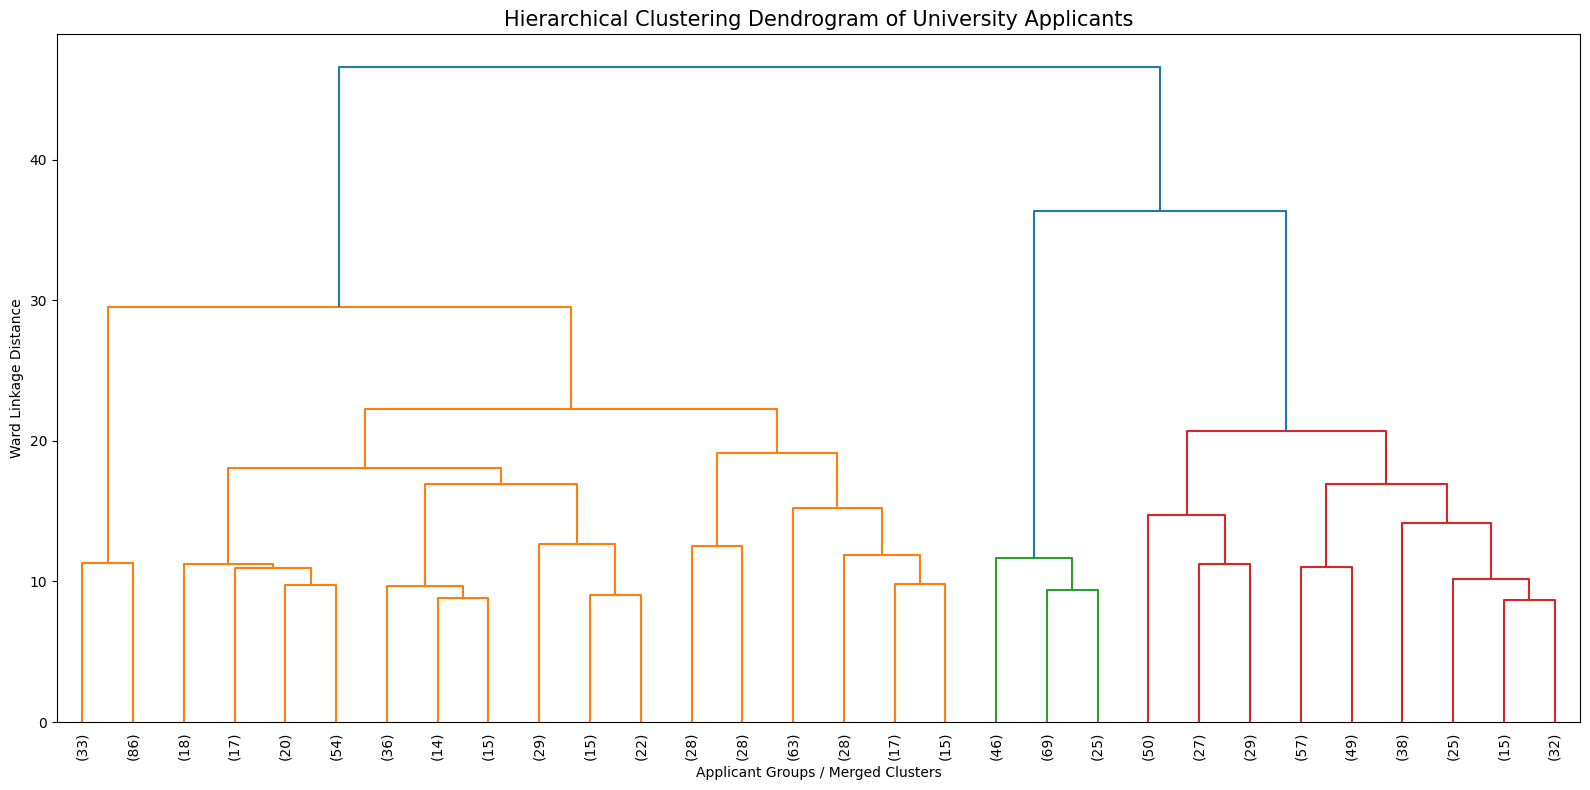

In [14]:
# Draw the dendrogram

from scipy.cluster.hierarchy import dendrogram

plt.figure(figsize=(16, 8))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title(
    "Hierarchical Clustering Dendrogram of University Applicants",
    fontsize=15
)

plt.xlabel("Applicant Groups / Merged Clusters")
plt.ylabel("Ward Linkage Distance")

plt.tight_layout()
plt.show()

In [13]:
# Select the number of clusters

from scipy.cluster.hierarchy import fcluster

# Initial cluster count for analysis
n_clusters = 4

df_clean["Applicant_Cluster"] = fcluster(
    Z,
    t=n_clusters,
    criterion="maxclust"
)

print("Applicant cluster counts:")
print(
    df_clean["Applicant_Cluster"]
    .value_counts()
    .sort_index()
)

Applicant cluster counts:
Applicant_Cluster
1    119
2    419
3    140
4    322
Name: count, dtype: int64


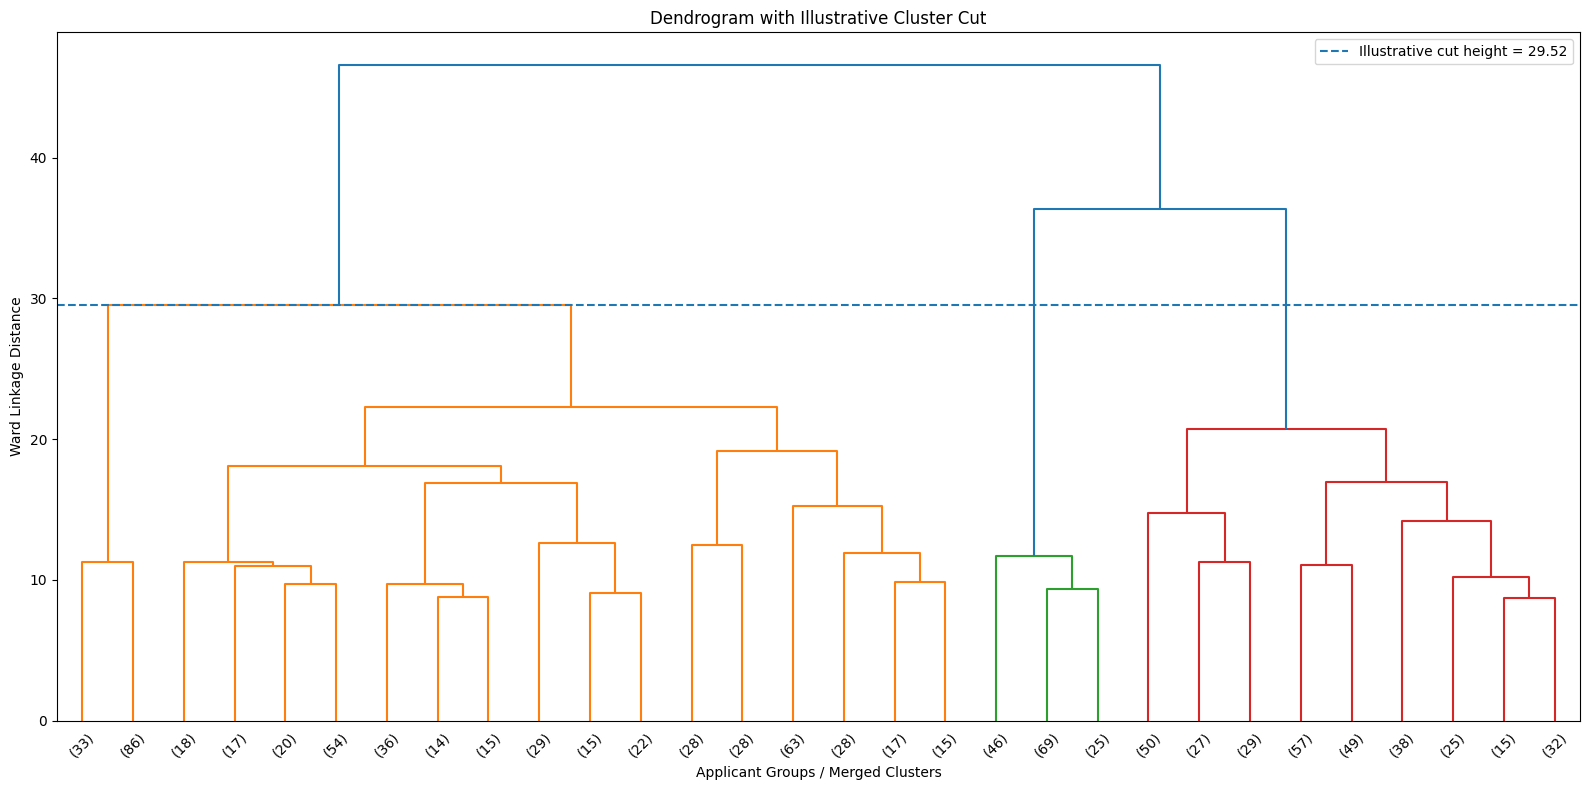

In [15]:
# Visualize the cluster cut on the dendrogram

from scipy.cluster.hierarchy import dendrogram

plt.figure(figsize=(16, 8))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

# Illustrative cut height; adjust after inspecting your dendrogram
cut_height = Z[-(n_clusters - 1), 2]

plt.axhline(
    y=cut_height,
    linestyle="--",
    label=f"Illustrative cut height = {cut_height:.2f}"
)

plt.title("Dendrogram with Illustrative Cluster Cut")
plt.xlabel("Applicant Groups / Merged Clusters")
plt.ylabel("Ward Linkage Distance")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# Analyze the characteristics of each applicant cluster

cluster_summary = (
    df_clean.groupby("Applicant_Cluster")[features]
    .mean()
    .round(2)
)

print("Average academic profile of each cluster:")
print(cluster_summary)


Average academic profile of each cluster:
                   GRE Score  TOEFL Score  University Rating   SOP   LOR  \
Applicant_Cluster                                                          
1                     307.09       100.71               2.08  2.24  2.57   
2                     314.21       106.61               2.88  3.48  3.52   
3                     327.97       113.74               4.49  4.39  4.16   
4                     316.30       105.55               2.90  3.27  3.24   

                   CGPA  Research  
Applicant_Cluster                  
1                  8.06      0.00  
2                  8.61      0.10  
3                  9.16      0.99  
4                  8.51      1.00  


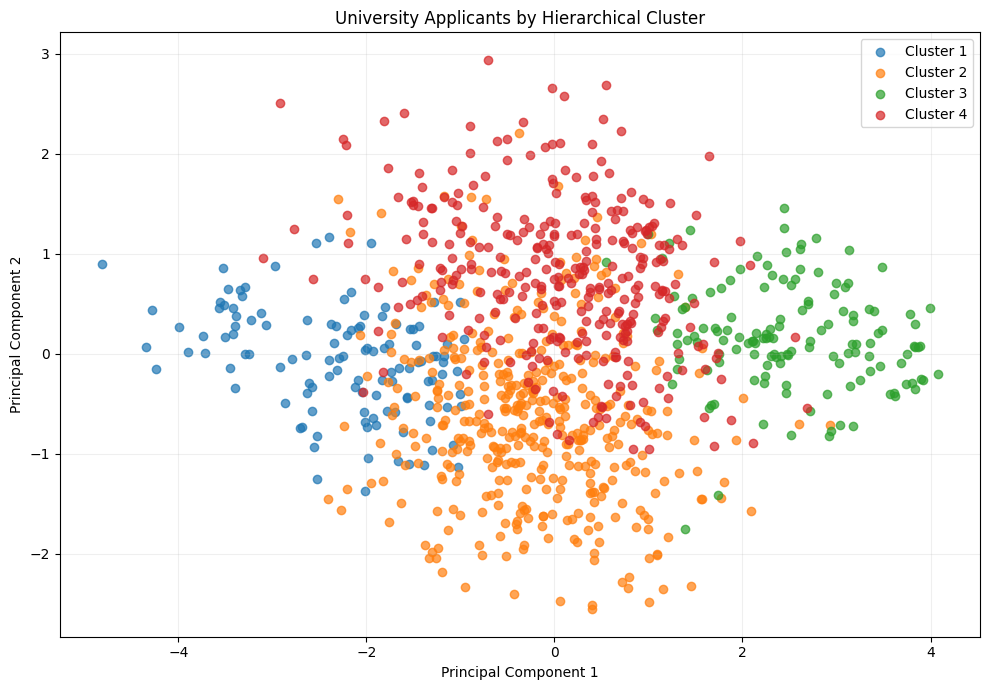

Variance explained by two components: 46.48 %


In [19]:
# Visualize the clusters in two dimensions

from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plot_data = pd.DataFrame({
    "Component 1": X_pca[:, 0],
    "Component 2": X_pca[:, 1],
    "Cluster": df_clean["Applicant_Cluster"].to_numpy()
})

plt.figure(figsize=(10, 7))

for cluster in sorted(plot_data["Cluster"].unique()):
    subset = plot_data[plot_data["Cluster"] == cluster]

    plt.scatter(
        subset["Component 1"],
        subset["Component 2"],
        label=f"Cluster {cluster}",
        alpha=0.7
    )

plt.title("University Applicants by Hierarchical Cluster")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

In [20]:
# Save the results to a CSV file

output_file = "Admission_Prediction_Hierarchical_Clusters.csv"

df_clean.to_csv(output_file, index=False)

print("Clustered dataset saved as:", output_file)

Clustered dataset saved as: Admission_Prediction_Hierarchical_Clusters.csv
